<a href="https://colab.research.google.com/github/yedabird/Pytorch-Tutorial-Youtube/blob/main/Basic_NeuralNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [25]:
# create a model class
class Model(nn.Module):
    # input layer (4 features of the input) -->
    #  Hidden layer 1 -->
    #  Hidden layer 2 -->
    #  output (3 classes)
    def __init__(self, in_features=4, h1=8, h2=9, out_features=3):
        super().__init__() #instantiate nn.Module
        self.fc1 = nn.Linear(in_features, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_features)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)
        return x


In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
%matplotlib inline

In [28]:
urls = "https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv"
data = pd.read_csv(urls)

In [29]:
data.head(5)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [30]:
data.tail(5)

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [31]:
#change species column from string to integer
data['species'] = data['species'].map({'setosa':0, 'versicolor':1, 'virginica':2})

In [32]:
data.head(5)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [33]:
data['species'].value_counts(dropna=False)

,count
species,
0,50
1,50
2,50


In [34]:
# train test split Set X, y

X = data.drop('species', axis=1)
y = data['species']
print(X.head(3)), print(y.head(3))

   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
0    0
1    0
2    0
Name: species, dtype: int64


(None, None)

In [35]:
# convert these to numpy array
X = X.values
y = y.values


In [36]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [37]:
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=41)

In [40]:
X_train.dtype

dtype('float64')

In [41]:
X_train = torch.FloatTensor(X_train) # convert float64 to default torch.float32
X_test = torch.FloatTensor(X_test)
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

In [42]:
X_train.dtype

torch.float32

In [121]:
torch.manual_seed(135)
model = Model()
# set the criterion of model to measure the rror, how far off the prediction are
ctiterion = nn.CrossEntropyLoss()
# Choose Adam Optimizer, lr - learning rate (if error doesn't go down after a bunch of iterations(epochs), lower our learning rate)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [122]:
for name, param in model.named_parameters():
    print(f"Layer: {name} | Size: {param.size()} | Values: \n{param.data}\n")

Layer: fc1.weight | Size: torch.Size([8, 4]) | Values: 
tensor([[-0.1998,  0.2669,  0.3898,  0.4107],
        [-0.4781,  0.1328,  0.4235, -0.2460],
        [-0.2741,  0.3689, -0.1692,  0.2802],
        [-0.2249,  0.4217,  0.2726, -0.1524],
        [-0.0457, -0.1856, -0.3525,  0.1325],
        [ 0.0698, -0.3096,  0.1818, -0.1163],
        [-0.2144, -0.0622,  0.0593, -0.4340],
        [-0.0282, -0.1000,  0.2940, -0.3253]])

Layer: fc1.bias | Size: torch.Size([8]) | Values: 
tensor([-0.2035, -0.4907, -0.1070,  0.0960,  0.0189,  0.0447,  0.2757,  0.2629])

Layer: fc2.weight | Size: torch.Size([9, 8]) | Values: 
tensor([[-0.2228,  0.2782, -0.1761, -0.2699,  0.0578,  0.2911,  0.3480,  0.3063],
        [-0.3124,  0.2457,  0.2152, -0.0030, -0.2241, -0.0890,  0.2669,  0.3177],
        [ 0.1698,  0.0946,  0.1739, -0.0986,  0.1779, -0.1971,  0.2589, -0.1786],
        [-0.0153, -0.0230, -0.3264,  0.3132, -0.0625,  0.3123,  0.0237, -0.0179],
        [-0.1948,  0.0244, -0.2473, -0.3102, -0.1536,  0.

In [123]:
# train model
# epochs (one run thru all the training data in the network)
epochs = 200
losses = []

torch.manual_seed(32)
for i in range(epochs):
    i += 1
    y_pred = model.forward(X_train)
    loss = ctiterion(y_pred, y_train)
    losses.append(loss.detach().numpy())

    if (i % 10==0):
      print(f" Epoch :{i} and loss: {loss}")

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# Corrected evaluation code snippet with the proper indentation inside the loop:
# correct = 0
# with torch.no_grad():
#     for i, data in enumerate(X_test):
#         y_val = model.forward(data)
#         print(f"{i+1:2}.\t {str(y_val):38}\t{y_test[i]}\t {y_val.argmax()}")
#
#         # INDENTED INSIDE THE LOOP:
#         if y_val.argmax().item() == y_test[i].item():
#             correct += 1
#             print("correct")
#
# print(f"we got {correct} correct!")

 Epoch :10 and loss: 1.041368007659912
 Epoch :20 and loss: 0.9294199347496033
 Epoch :30 and loss: 0.7612305879592896
 Epoch :40 and loss: 0.6675072908401489
 Epoch :50 and loss: 0.5928972959518433
 Epoch :60 and loss: 0.5040444135665894
 Epoch :70 and loss: 0.3964727520942688
 Epoch :80 and loss: 0.27428168058395386
 Epoch :90 and loss: 0.17103320360183716
 Epoch :100 and loss: 0.10605327785015106
 Epoch :110 and loss: 0.07189987599849701
 Epoch :120 and loss: 0.054228778928518295
 Epoch :130 and loss: 0.04428386315703392
 Epoch :140 and loss: 0.03806520998477936
 Epoch :150 and loss: 0.03378615900874138
 Epoch :160 and loss: 0.03063041716814041
 Epoch :170 and loss: 0.02816496044397354
 Epoch :180 and loss: 0.026160281151533127
 Epoch :190 and loss: 0.024480225518345833
 Epoch :200 and loss: 0.023035790771245956


Text(0.5, 1.0, 'loss')

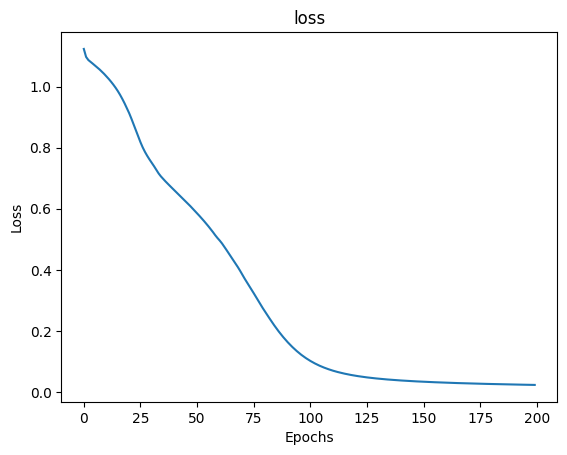

In [124]:
plt.plot(range(epochs), losses)
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.title("loss")

In [125]:
# evaluate model on test data
with torch.no_grad():
    y_eval = model.forward(X_test)
    loss = ctiterion(y_eval, y_test)
print(f"Test loss: {loss}")

Test loss: 0.16133227944374084


In [126]:
correct = 0
with torch.no_grad():
    for i, data in enumerate(X_test):
        y_val = model.forward(data)
        if y_test[i]==0:
          x = "Setosa"
        elif y_test[i]==1:
          x = "Versicolor"
        else:
          x = "Virginica"

        is_correct = y_val.argmax().item() == y_test[i]
        print(f"{i+1:2}.\t {str(y_val)}\t{y_test[i]}\t {y_val.argmax()}\t {'(Correct)' if is_correct else '(Incorrect)'}, {x}")

        if is_correct:
            correct += 1

print(f"\nWe got {correct} correct!")
print(f"{correct} out of {len(y_test)} = {100*correct/len(y_test):.2f}% correct")

 1.	 tensor([-6.9141,  2.6868,  6.8580])	2	 2	 (Correct), Virginica
 2.	 tensor([-9.3965,  0.4688, 12.9528])	2	 2	 (Correct), Virginica
 3.	 tensor([-10.0575,   1.2792,  12.8720])	2	 2	 (Correct), Virginica
 4.	 tensor([-4.8994,  6.2746, -0.2159])	1	 1	 (Correct), Versicolor
 5.	 tensor([-8.6463,  2.1823,  9.8578])	2	 2	 (Correct), Virginica
 6.	 tensor([-3.8356,  5.4017, -0.6784])	1	 1	 (Correct), Versicolor
 7.	 tensor([-6.8891,  3.6228,  5.7055])	2	 2	 (Correct), Virginica
 8.	 tensor([-5.0955,  6.0349,  0.3483])	1	 1	 (Correct), Versicolor
 9.	 tensor([-7.8227,  2.9594,  7.7939])	2	 2	 (Correct), Virginica
10.	 tensor([-10.0804,   0.4984,  13.8634])	2	 2	 (Correct), Virginica
11.	 tensor([-6.7701,  3.9652,  5.1420])	2	 2	 (Correct), Virginica
12.	 tensor([ 3.3238, -2.0737, -2.6024])	0	 0	 (Correct), Setosa
13.	 tensor([ 3.3238, -2.0737, -2.6024])	0	 0	 (Correct), Setosa
14.	 tensor([-2.7038,  4.0874, -0.7839])	1	 1	 (Correct), Versicolor
15.	 tensor([ 2.8880, -1.6036, -2.5340])	0	 

In [128]:
model.state_dict()

OrderedDict([('fc1.weight',
              tensor([[-0.1889, -0.1583,  0.9723,  1.1318],
                      [-0.4781,  0.1328,  0.4235, -0.2460],
                      [-0.2741,  0.3689, -0.1692,  0.2802],
                      [-0.6678, -0.0817,  0.8273,  0.9719],
                      [-0.0457, -0.1856, -0.3525,  0.1325],
                      [-0.2680, -0.7830,  0.7323,  1.0431],
                      [-0.2144, -0.0622,  0.0593, -0.4340],
                      [-0.1408, -0.2132,  0.1809, -0.4391]])),
             ('fc1.bias',
              tensor([-0.5124, -0.4907, -0.1070, -0.8423,  0.0189, -0.9844,  0.2757,  0.1509])),
             ('fc2.weight',
              tensor([[-0.2228,  0.2782, -0.1761, -0.2699,  0.0578,  0.2911,  0.3480,  0.3063],
                      [-0.3124,  0.2457,  0.2152, -0.0030, -0.2241, -0.0890,  0.2669,  0.3177],
                      [ 1.1461,  0.0946,  0.1739, -0.2828,  0.1779, -0.3877,  0.2589, -0.0557],
                      [ 0.3416, -0.0230, -0.3264, 

In [129]:
# save the model
torch.save(model.state_dict(), 'awesome_iris_model.pt')

In [130]:
# load the model
new_model = Model()
new_model.load_state_dict(torch.load('awesome_iris_model.pt'))

#

<All keys matched successfully>

In [ ]:
# make sure it loads correctly

In [131]:
new_model.eval()

Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)

In [135]:
criterion = nn.CrossEntropyLoss()
with torch.no_grad():
  predicted = new_model(X_test)
  loss = criterion(predicted, y_test)
print(f" model test loss: {loss}")


 model test loss: 0.16133227944374084
